# PIZZA SALES PROJECT

In [2]:
import pandas as pd

In [3]:
import os

In [4]:
print(os.getcwd())

C:\Users\esthe


In [5]:
print([f for f in os.listdir() if f.endswith(".csv")])

[]


In [6]:
df = pd.read_csv(r"C:\Users\esthe\Downloads\pizza_sales.csv")

In [7]:
# Parse dates/times (dd/mm/yyyy)

In [8]:
df["order_date"] = pd.to_datetime(df["order_date"], format="%d/%m/%Y")

In [9]:
df["order_time"] = pd.to_datetime(df["order_time"], format="%H:%M:%S").dt.time

In [12]:
# Derived time columns

df["month"] = df["order_date"].dt.month
df["month_name"] = df["order_date"].dt.strftime("%b")
df["weekday"] = df["order_date"].dt.day_name()
df["hour"] = df["order_time"].apply(lambda t: t.hour)

In [13]:
# Tidy text columns

df["pizza_size"] = pd.Categorical(
    df["pizza_size"], categories=["S", "M", "L", "XL", "XXL"], ordered=True
)

In [14]:
# Sanity checks

print(df.shape)
print(df[["order_date", "month", "weekday", "hour"]].head())
print(df["order_date"].min(), df["order_date"].max())

(48620, 16)
  order_date  month   weekday  hour
0 2015-01-01      1  Thursday    11
1 2015-01-01      1  Thursday    11
2 2015-01-01      1  Thursday    11
3 2015-01-01      1  Thursday    11
4 2015-01-01      1  Thursday    11
2015-01-01 00:00:00 2015-12-31 00:00:00


In [16]:
# --- Headline KPIs ---

total_revenue = df["total_price"].sum()
total_orders = df["order_id"].nunique()
total_pizzas = df["quantity"].sum()
aov = total_revenue / total_orders
pizzas_per_order = total_pizzas / total_orders


print(f"Revenue: ${total_revenue:,.2f}")
print(f"Orders: {total_orders:,}")
print(f"Pizzas sold: {total_pizzas:,}")
print(f"AOV: ${aov:.2f}")
print(f"Pizzas per order: {pizzas_per_order:.2f}")

Revenue: $817,860.05
Orders: 21,350
Pizzas sold: 49,574
AOV: $38.31
Pizzas per order: 2.32


In [17]:
# --- Monthly (revenue per trading day corrects for missing days) ---

monthly = df.groupby("month").agg(
    revenue=("total_price", "sum"),
    orders=("order_id", "nunique"),
    trading_days=("order_date", "nunique"),
)
monthly["revenue_per_day"] = monthly["revenue"] / monthly["trading_days"]


In [19]:
# --- Day of week ---

weekday = df.groupby("weekday").agg(
    revenue=("total_price", "sum"),
    orders=("order_id", "nunique"),
    trading_days=("order_date", "nunique"),
)

weekday["orders_per_day"] = weekday["orders"] / weekday["trading_days"]
weekday = weekday.reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])

In [20]:
# --- Hour of day ---

hourly = df.groupby("hour").agg(
    revenue=("total_price", "sum"),
    orders=("order_id", "nunique"),
)

In [21]:
Headline numbers

Total revenue: $817,860.05
Orders: 21,350
Pizzas sold: 49,574 (this is the sum of quantity, not the 48,620 row count)
AOV: $38.31
About 2.32 pizzas per order

SyntaxError: invalid syntax (3844281105.py, line 1)

In [24]:
total_rev = df["total_price"].sum()

# --- By pizza ---
pizza = df.groupby("pizza_name").agg(
    revenue=("total_price", "sum"),
    quantity=("quantity", "sum"),
    orders=("order_id", "nunique"),
)

top_rev = pizza.sort_values("revenue", ascending=False).head(5)
bottom_rev = pizza.sort_values("revenue").head(5)
top_qty = pizza.sort_values("quantity", ascending=False).head(5)
bottom_qty = pizza.sort_values("quantity").head(5)

In [26]:
# --- By category ---

category = df.groupby("pizza_category").agg(
    revenue=("total_price", "sum"),
    quantity=("quantity", "sum"),
)

category["revenue_pct"] = category["revenue"] / total_rev * 100
category["quantity_pct"] = category["quantity"] / category["quantity"].sum() * 100


In [27]:
# --- By size ---

size = df.groupby("pizza_size").agg(
    revenue=("total_price", "sum"),
    quantity=("quantity", "sum"),
)
size["revenue_pct"] = size["revenue"] / total_rev * 100
size["quantity_pct"] = size["quantity"] / size["quantity"].sum() * 100

C:\Users\esthe\AppData\Local\Temp\ipykernel_20792\2136138984.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  size = df.groupby("pizza_size").agg(


In [29]:
total_rev = df["total_price"].sum()
total_qty = df["quantity"].sum()

category_table = (
    df.groupby("pizza_category")
      .agg(revenue=("total_price", "sum"), units=("quantity", "sum"))
)

category_table["Revenue share"] = (category_table["revenue"] / total_rev * 100).round(1).astype(str) + "%"
category_table["Units share"] = (category_table["units"] / total_qty * 100).round(1).astype(str) + "%"

# Keep only the two share columns, sort by revenue, and tidy the labels
category_table = (
    category_table.sort_values("revenue", ascending=False)
                  [["Revenue share", "Units share"]]
                  .rename_axis("Category")
)

category_table

,Revenue share,Units share
Category,,
Classic,26.9%,30.0%
Supreme,25.5%,24.2%
Chicken,24.0%,22.3%
Veggie,23.7%,23.5%


In [30]:
# --- Monthly (revenue per trading day corrects for missing days) ---

monthly = df.groupby("month").agg(
    revenue=("total_price", "sum"),
    orders=("order_id", "nunique"),
    trading_days=("order_date", "nunique"),
)
monthly["revenue_per_day"] = monthly["revenue"] / monthly["trading_days"]

# --- Day of week ---

weekday = df.groupby("weekday").agg(
    revenue=("total_price", "sum"),
    orders=("order_id", "nunique"),
    trading_days=("order_date", "nunique"),
)

weekday["orders_per_day"] = weekday["orders"] / weekday["trading_days"]
weekday = weekday.reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])


# --- Hour of day ---

hourly = df.groupby("hour").agg(
    revenue=("total_price", "sum"),
    orders=("order_id", "nunique"),
)

In [31]:
# --- Headline KPIs ---
total_revenue = df["total_price"].sum()
total_orders = df["order_id"].nunique()
total_pizzas = df["quantity"].sum()
aov = total_revenue / total_orders
pizzas_per_order = total_pizzas / total_orders

print(f"Revenue: ${total_revenue:,.2f}")
print(f"Orders: {total_orders:,}")
print(f"Pizzas sold: {total_pizzas:,}")
print(f"AOV: ${aov:.2f}")
print(f"Pizzas per order: {pizzas_per_order:.2f}")

# --- Monthly (revenue per trading day corrects for missing days) ---
monthly = df.groupby("month").agg(
    revenue=("total_price", "sum"),
    orders=("order_id", "nunique"),
    trading_days=("order_date", "nunique"),
)
monthly["revenue_per_day"] = monthly["revenue"] / monthly["trading_days"]

# --- Day of week ---
weekday = df.groupby("weekday").agg(
    revenue=("total_price", "sum"),
    orders=("order_id", "nunique"),
    trading_days=("order_date", "nunique"),
)
weekday["orders_per_day"] = weekday["orders"] / weekday["trading_days"]
weekday = weekday.reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])

# --- Hour of day ---
hourly = df.groupby("hour").agg(
    revenue=("total_price", "sum"),
    orders=("order_id", "nunique"),
)

Revenue: $817,860.05
Orders: 21,350
Pizzas sold: 49,574
AOV: $38.31
Pizzas per order: 2.32


In [32]:
# --- One row per order ---

orders = df.groupby("order_id").agg(
    pizzas=("quantity", "sum"),
    revenue=("total_price", "sum"),
    distinct_pizzas=("pizza_name", "nunique"),
)

print(orders["pizzas"].describe())

# Basket size distribution
basket_dist = orders["pizzas"].value_counts().sort_index()
basket_pct = (basket_dist / len(orders) * 100).round(1)

# Revenue by basket-size band
bands = pd.cut(orders["pizzas"], [0, 1, 2, 3, 4, 100],
               labels=["1", "2", "3", "4", "5+"])
band_summary = orders.groupby(bands, observed=True).agg(
    orders=("revenue", "count"),
    avg_order_value=("revenue", "mean"),
    total_revenue=("revenue", "sum"),
)
band_summary["revenue_share_%"] = (band_summary["total_revenue"] / orders["revenue"].sum() * 100).round(1)

# --- Pizzas bought together (pairs of different pizzas in the same order) ---
from itertools import combinations
from collections import Counter

baskets = df.groupby("order_id")["pizza_name"].apply(lambda s: sorted(set(s)))
pairs = Counter()
for names in baskets:
    for a, b in combinations(names, 2):
        pairs[(a, b)] += 1

pairs_df = pd.DataFrame(pairs.most_common(10), columns=["pair", "orders"])

count    21350.000000
mean         2.321967
std          1.825735
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         28.000000
Name: pizzas, dtype: float64


In [33]:
The takeaway is that the 3,880 orders with 4+ pizzas (about 18% of orders) bring in about 39% of revenue. Meanwhile the biggest group by count, single-pizza orders, brings in only 16%. Nudging a 1-pizza customer to 2 doubles that order's value.

Pizzas bought together

The top pairs are things like Hawaiian + Thai Chicken (270 orders), BBQ Chicken + Pepperoni (269) and Hawaiian + Pepperoni (259).
I'd be careful reading anything into this. These are simply the most popular pizzas, so they naturally show up together most. The counts are tightly bunched (about 250 to 270), which suggests there's no strong "these two go together" effect. To find real affinities you'd need to compare against how often the pair would co-occur by chance (a "lift" calculation), which I can show you if you want it.
At category level, 61% of orders contain two or more different pizzas, and about half mix sizes. Classic + Veggie is the most common category pairing (4,041 orders), but all six pairings sit in a similar range, so customers mix freely across categories.

For the write-up

Basket size is the biggest lever: combos or "add a second pizza for $X" offers target the 38% of single-pizza orders.
A "family" bundle at 4 pizzas matches existing behaviour, since that's where baskets naturally peak.
Cross-sell recommendations based on pairs aren't strongly supported by this data, so I'd say so rather than overclaim.


SyntaxError: unterminated string literal (detected at line 1) (1205963974.py, line 1)

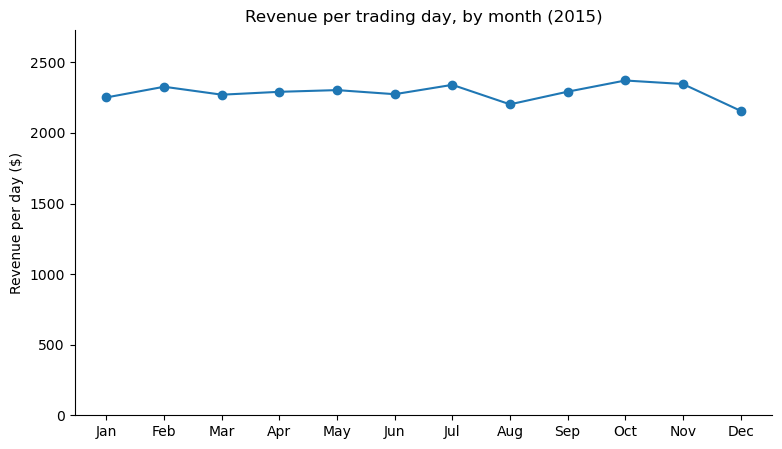

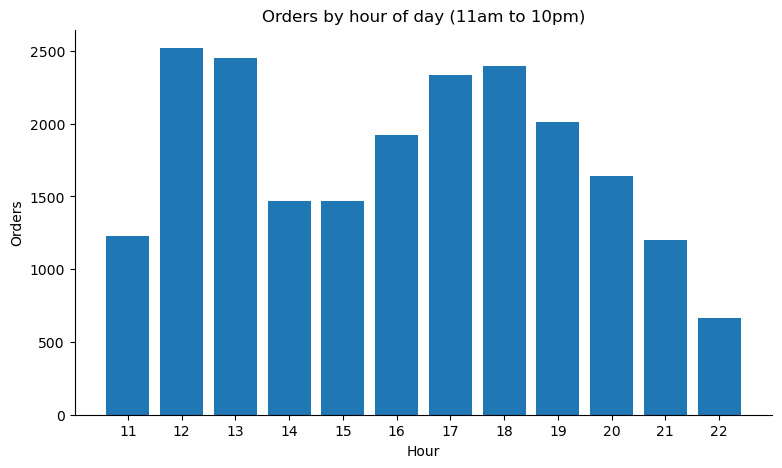

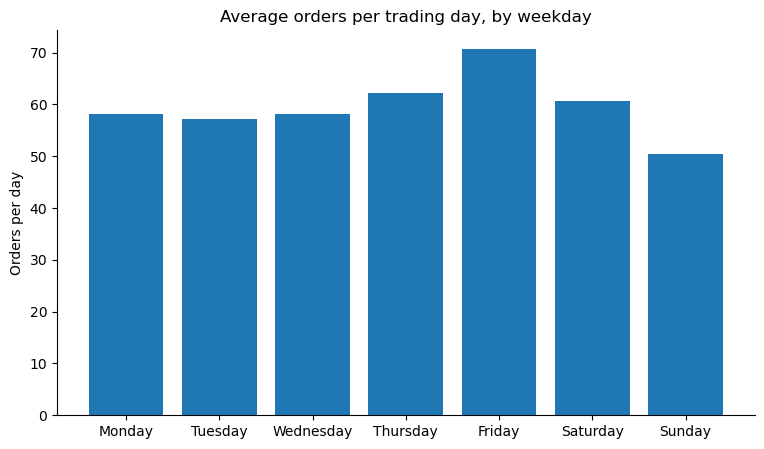

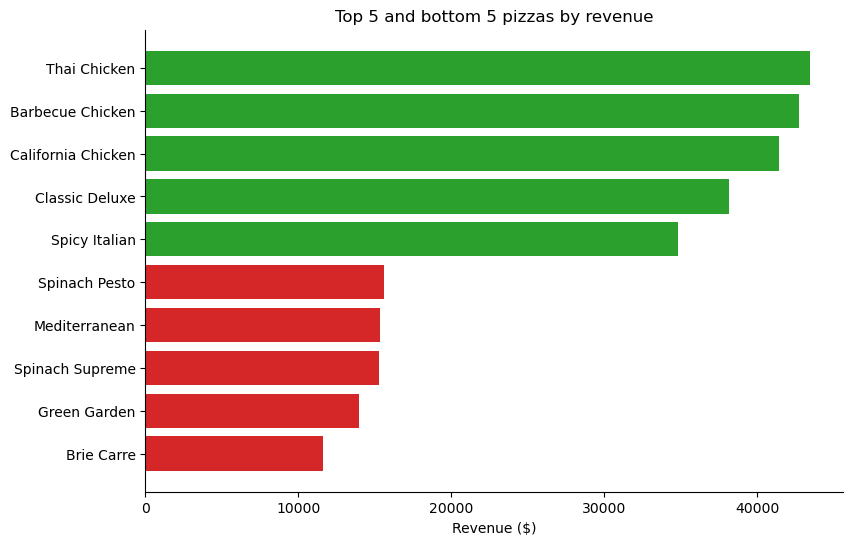

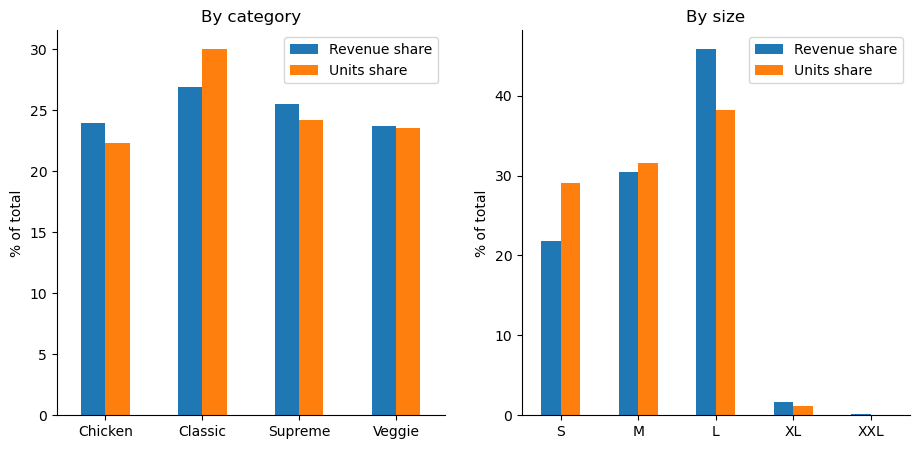

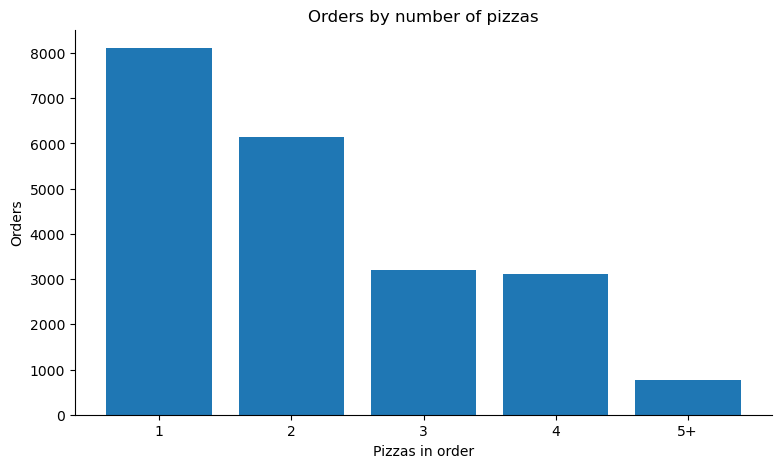

In [34]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({"figure.figsize": (9, 5),
                     "axes.spines.top": False,
                     "axes.spines.right": False})

# 1. Revenue per trading day, by month
m = df.groupby("month").agg(rev=("total_price", "sum"), days=("order_date", "nunique"))
m["per_day"] = m["rev"] / m["days"]
fig, ax = plt.subplots()
ax.plot(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"],
        m["per_day"], marker="o")
ax.set_ylim(0, m["per_day"].max() * 1.15)
ax.set_title("Revenue per trading day, by month (2015)")
ax.set_ylabel("Revenue per day ($)")
plt.show()

# 2. Orders by hour (11am to 10pm only, to skip the stray 9-10am and 11pm orders)
h = df.groupby("hour")["order_id"].nunique()
h = h[(h.index >= 11) & (h.index <= 22)]
fig, ax = plt.subplots()
ax.bar(h.index, h.values)
ax.set_xticks(h.index)
ax.set_title("Orders by hour of day (11am to 10pm)")
ax.set_xlabel("Hour")
ax.set_ylabel("Orders")
plt.show()

# 3. Average orders per trading day, by weekday
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
w = (df.groupby("weekday")
       .agg(orders=("order_id", "nunique"), days=("order_date", "nunique"))
       .reindex(order))
w["per_day"] = w["orders"] / w["days"]
fig, ax = plt.subplots()
ax.bar(order, w["per_day"])
ax.set_title("Average orders per trading day, by weekday")
ax.set_ylabel("Orders per day")
plt.show()

# 4. Top 5 and bottom 5 pizzas by revenue
rev = df.groupby("pizza_name")["total_price"].sum().sort_values()
extremes = pd.concat([rev.head(5), rev.tail(5)])
colors = ["tab:red"] * 5 + ["tab:green"] * 5
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(extremes.index.str.replace("The ", "").str.replace(" Pizza", ""),
        extremes.values, color=colors)
ax.set_title("Top 5 and bottom 5 pizzas by revenue")
ax.set_xlabel("Revenue ($)")
plt.show()

# 5. Category and size mix: revenue share vs units share
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, col, title in zip(axes, ["pizza_category", "pizza_size"], ["By category", "By size"]):
    g = df.groupby(col, observed=True).agg(rev=("total_price", "sum"), qty=("quantity", "sum"))
    shares = pd.DataFrame({
        "Revenue share": g["rev"] / g["rev"].sum() * 100,
        "Units share": g["qty"] / g["qty"].sum() * 100,
    })
    shares.plot.bar(ax=ax, rot=0)
    ax.set_title(title)
    ax.set_ylabel("% of total")
    ax.set_xlabel("")
plt.show()

# 6. Basket size distribution (5+ grouped together)
o = df.groupby("order_id")["quantity"].sum()
b = o.clip(upper=5).value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(["1", "2", "3", "4", "5+"], b.values)
ax.set_title("Orders by number of pizzas")
ax.set_xlabel("Pizzas in order")
ax.set_ylabel("Orders")
plt.show()

In [35]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({"figure.figsize": (9, 5),
                     "axes.spines.top": False,
                     "axes.spines.right": False})

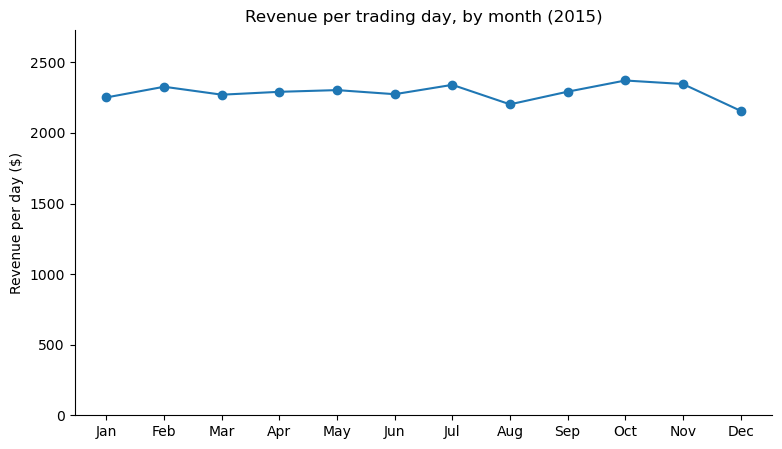

In [36]:
# 1. Revenue per trading day, by month
m = df.groupby("month").agg(rev=("total_price", "sum"), days=("order_date", "nunique"))
m["per_day"] = m["rev"] / m["days"]
fig, ax = plt.subplots()
ax.plot(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"],
        m["per_day"], marker="o")
ax.set_ylim(0, m["per_day"].max() * 1.15)
ax.set_title("Revenue per trading day, by month (2015)")
ax.set_ylabel("Revenue per day ($)")
plt.show()

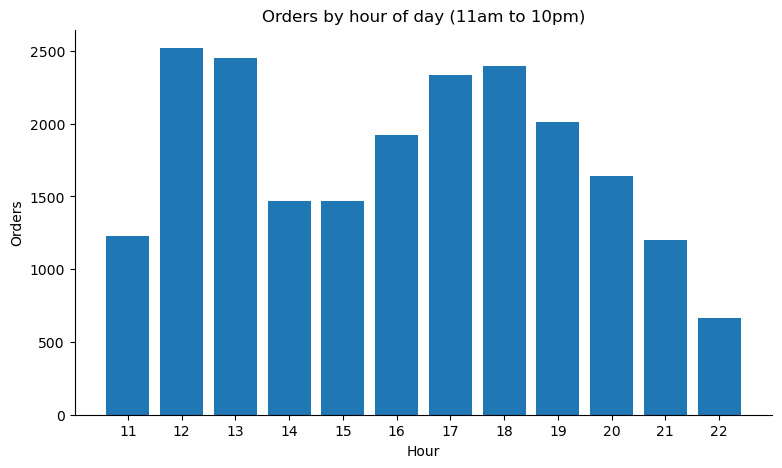

In [37]:
# 2. Orders by hour (11am to 10pm only, to skip the stray 9-10am and 11pm orders)
h = df.groupby("hour")["order_id"].nunique()
h = h[(h.index >= 11) & (h.index <= 22)]
fig, ax = plt.subplots()
ax.bar(h.index, h.values)
ax.set_xticks(h.index)
ax.set_title("Orders by hour of day (11am to 10pm)")
ax.set_xlabel("Hour")
ax.set_ylabel("Orders")
plt.show()

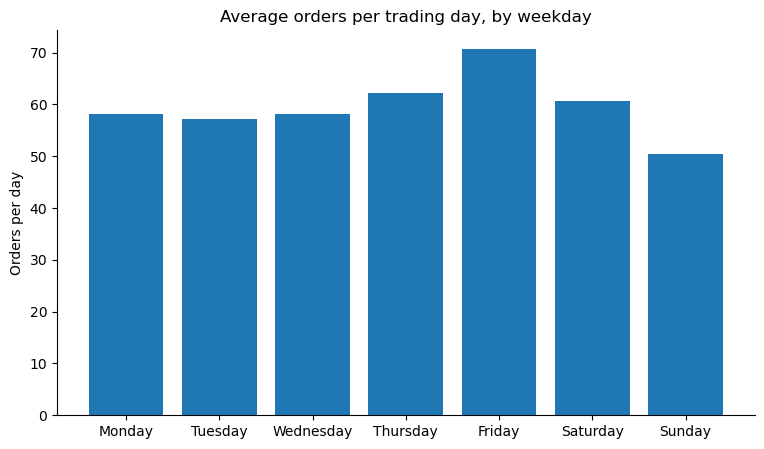

In [38]:
# 3. Average orders per trading day, by weekday
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
w = (df.groupby("weekday")
       .agg(orders=("order_id", "nunique"), days=("order_date", "nunique"))
       .reindex(order))
w["per_day"] = w["orders"] / w["days"]
fig, ax = plt.subplots()
ax.bar(order, w["per_day"])
ax.set_title("Average orders per trading day, by weekday")
ax.set_ylabel("Orders per day")
plt.show()

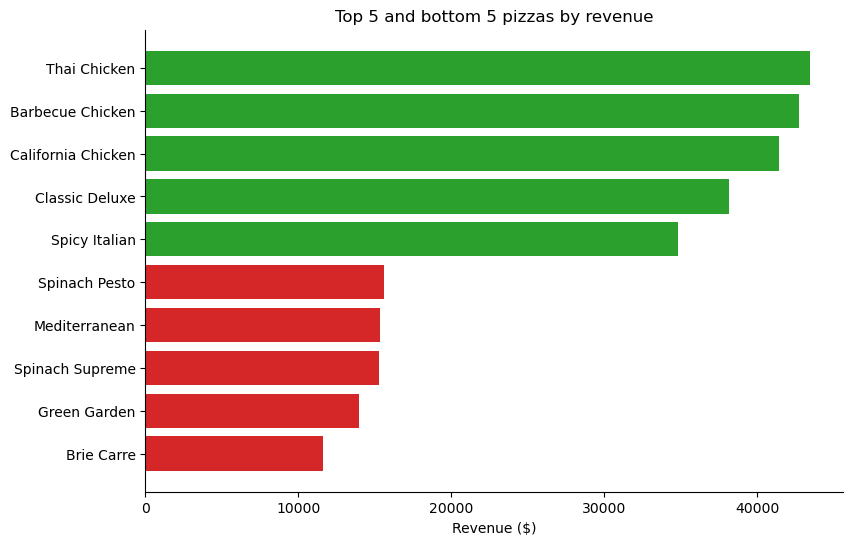

In [39]:
# 4. Top 5 and bottom 5 pizzas by revenue
rev = df.groupby("pizza_name")["total_price"].sum().sort_values()
extremes = pd.concat([rev.head(5), rev.tail(5)])
colors = ["tab:red"] * 5 + ["tab:green"] * 5
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(extremes.index.str.replace("The ", "").str.replace(" Pizza", ""),
        extremes.values, color=colors)
ax.set_title("Top 5 and bottom 5 pizzas by revenue")
ax.set_xlabel("Revenue ($)")
plt.show()

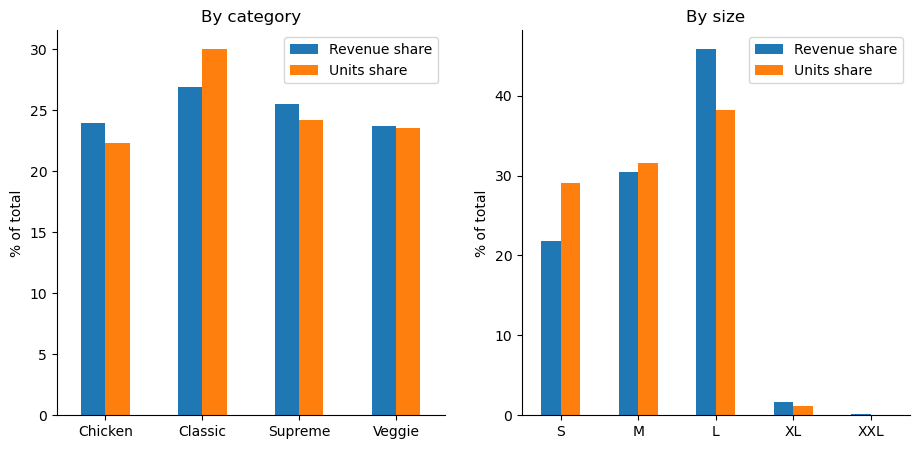

In [40]:
# 5. Category and size mix: revenue share vs units share
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, col, title in zip(axes, ["pizza_category", "pizza_size"], ["By category", "By size"]):
    g = df.groupby(col, observed=True).agg(rev=("total_price", "sum"), qty=("quantity", "sum"))
    shares = pd.DataFrame({
        "Revenue share": g["rev"] / g["rev"].sum() * 100,
        "Units share": g["qty"] / g["qty"].sum() * 100,
    })
    shares.plot.bar(ax=ax, rot=0)
    ax.set_title(title)
    ax.set_ylabel("% of total")
    ax.set_xlabel("")
plt.show()


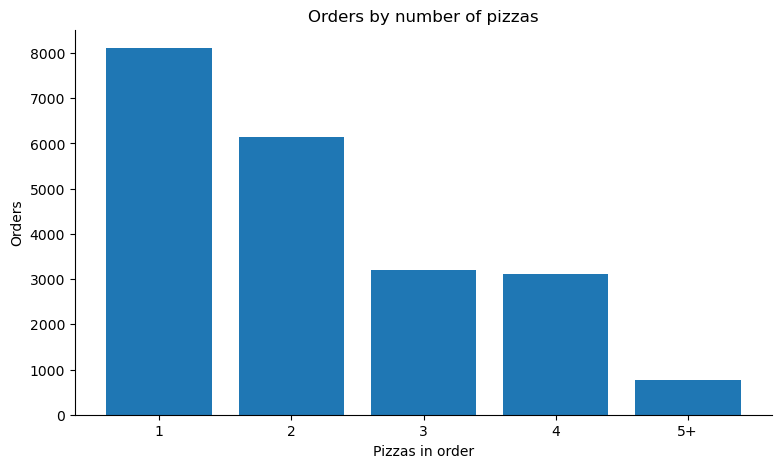

In [41]:
# 6. Basket size distribution (5+ grouped together)
o = df.groupby("order_id")["quantity"].sum()
b = o.clip(upper=5).value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(["1", "2", "3", "4", "5+"], b.values)
ax.set_title("Orders by number of pizzas")
ax.set_xlabel("Pizzas in order")
ax.set_ylabel("Orders")
plt.show()

In [42]:
fig.savefig("monthly_trend.png", dpi=150, bbox_inches="tight")